# A machine-learning-ready particle table: features, labels and a grouped split

The image-processing stage writes one row of measurements per particle (sizes, area, perimeter,
axis ratio, edge contact, inter-arrival time). The triage tool writes one verdict per reviewed
particle. Joined on the particle index, the two make a training table: the measurements are the
features and the verdicts are the targets.

This notebook builds that table on synthetic particles, writes demonstration verdicts in the
triage tool's documented label file format, keeps only the labels fit to train on, and splits the rows by
file so that no file contributes to both training and testing. Worked on fixed-seed synthetic data.

**Before this:** [06_read_products](../1_getting_started/06_read_products.ipynb) (Reading the output files). **Related:** [04_output_formats_and_tables](04_output_formats_and_tables.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/7_analysis_and_outputs/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

## Synthetic per-particle measurements

Six synthetic files of 400 particles each. Each particle is either a real particle (larger,
rounder, well separated in time) or an artifact (small, elongated, often touching the array edge,
arriving in bursts). The columns carry the names the image-processing output uses. Each file gets
its own small offset in size and timing, as real files differ in conditions.

In [2]:
import json, tempfile
import numpy as np
import pandas as pd

rng = np.random.default_rng(39)
FILES = [f"synthetic_{c}" for c in "ABCDEF"]
N_PER_FILE = 400

rows = []
for name in FILES:
    shift = rng.normal(0.0, 0.15)                      # per-file condition offset
    is_real = rng.random(N_PER_FILE) < 0.55
    d = np.where(is_real, rng.lognormal(np.log(0.20) + shift, 0.5, N_PER_FILE),
                 rng.lognormal(np.log(0.06) + shift, 0.4, N_PER_FILE))          # mm
    axis_ratio = np.where(is_real, rng.uniform(0.6, 1.0, N_PER_FILE),
                          rng.uniform(0.15, 0.7, N_PER_FILE))
    area = np.pi / 4 * d**2 * axis_ratio * rng.uniform(0.85, 1.0, N_PER_FILE)
    perimeter = np.pi * d * (1 + axis_ratio) / 2 * rng.uniform(1.0, 1.3, N_PER_FILE)
    touching = (rng.random(N_PER_FILE) < np.where(is_real, 0.05, 0.35)).astype(int)
    interarrival = np.where(is_real, rng.exponential(2e-3, N_PER_FILE),
                            rng.exponential(2e-5, N_PER_FILE)) * np.exp(shift)  # s
    rows.append(pd.DataFrame({
        "file": name, "particle_index": np.arange(N_PER_FILE),
        "image_diam_minR": d, "image_area": area, "image_perimeter": perimeter,
        "image_axis_ratio": axis_ratio, "image_touching_edge": touching,
        "inter_arrival": interarrival, "truth_real": is_real}))
particles = pd.concat(rows, ignore_index=True)
print(particles.shape)
print(particles.drop(columns="truth_real").head().round(5).to_string())

(2400, 9)
          file  particle_index  image_diam_minR  image_area  image_perimeter  image_axis_ratio  image_touching_edge  inter_arrival
0  synthetic_A               0          0.18020     0.02082          0.67545           0.91114                    0        0.00140
1  synthetic_A               1          0.08299     0.00336          0.22968           0.71975                    0        0.00331
2  synthetic_A               2          0.19989     0.02217          0.56525           0.76674                    0        0.00008
3  synthetic_A               3          0.03535     0.00041          0.09708           0.47691                    0        0.00004
4  synthetic_A               4          0.06065     0.00188          0.18674           0.65593                    1        0.00020


## Verdicts in the triage label file format

A reviewer labels 150 particles of each file. The triage tool stores labels as plain JSON, one
sidecar per file under `triage_verdicts/`, keyed by particle index; the format is documented in
[Tune thresholds on your own flight](../../docs/43-tune-thresholds.md#label-file-format). Every record
states its verdict, its source (`human`, `bulk-cluster` or `model`), its reviewer, when it was made
and the package version. A relabelled particle keeps its earlier records in `history`, oldest
first. The demonstration reviewer is mostly right, sometimes `unsure`, and marks a few images
`mixed` (two particles in one image). Half of one file's labels come from a clustering pass
instead (`bulk-cluster`), as happens when labels are propagated in bulk. A few particles are
relabelled after a second look, so their records carry a `history`.

In [3]:
import arrayprobe

decoded = Path(tempfile.mkdtemp(prefix="nb39_"))
(decoded / "triage_verdicts").mkdir()
STAMP = "2026-01-01T00:00:00+00:00"                     # fixed, so the demo is reproducible

def label(verdict, source, at=STAMP):
    return {"verdict": verdict, "note": "", "source": source, "at": at,
            "tool": arrayprobe.__version__, "reviewer": "demo-reviewer"}

for name, grp in particles.groupby("file"):
    picked = grp.sample(150, random_state=int(rng.integers(1 << 31)))
    sidecar = {}
    for p in picked.itertuples():
        u = rng.random()
        if u < 0.06:
            verdict = "unsure"
        elif u < 0.09:
            verdict = "mixed"
        elif u < 0.96:
            verdict = "real" if p.truth_real else "artifact"
        else:
            verdict = "artifact" if p.truth_real else "real"   # reviewer error
        source = "bulk-cluster" if (name == "synthetic_F" and rng.random() < 0.5) else "human"
        rec = label(verdict, source)
        if verdict == "unsure" and rng.random() < 0.5:   # a second look settles it
            rec = label("real" if p.truth_real else "artifact", source,
                        at="2026-01-02T00:00:00+00:00")
            rec["history"] = [label("unsure", source)]
        sidecar[str(int(p.particle_index))] = rec
    (decoded / "triage_verdicts" / f"{name}.json").write_text(json.dumps(sidecar, indent=1))

sidecar = json.loads((decoded / "triage_verdicts" / "synthetic_A.json").read_text())
key = next(k for k, r in sidecar.items() if "history" in r)
print(f"synthetic_A.json: {len(sidecar)} records; a relabelled particle, {key}:")
print(json.dumps({k: v for k, v in sidecar[key].items() if k != "tool"}, indent=1))

synthetic_A.json: 150 records; a relabelled particle, 84:
{
 "verdict": "real",
 "note": "",
 "source": "human",
 "at": "2026-01-02T00:00:00+00:00",
 "reviewer": "demo-reviewer",
 "history": [
  {
   "verdict": "unsure",
   "note": "",
   "source": "human",
   "at": "2026-01-01T00:00:00+00:00",
   "tool": "0.1.0",
   "reviewer": "demo-reviewer"
  }
 ]
}


## From records to targets

Each sidecar is read back with the `json` module; the top-level fields of a record are the current
label. Only labels that can serve as ground truth are kept: source `human`, and a verdict other
than `unsure` (the reviewer could not decide) or `mixed` (one label is the wrong shape for the
image). The tally shows what each filter removes.

In [4]:
EXCLUDED = {"unsure", "mixed"}
records = []
for name in FILES:
    stored = json.loads((decoded / "triage_verdicts" / f"{name}.json").read_text())
    for key, rec in stored.items():
        records.append({"file": name, "particle_index": int(key), "verdict": rec["verdict"],
                        "source": rec.get("source"), "relabelled": "history" in rec})
labels = pd.DataFrame(records)
print(pd.crosstab(labels.verdict, labels.source))
print()
print(f"{labels.relabelled.sum()} records carry an earlier label in their history")

usable = labels[(labels.source == "human") & ~labels.verdict.isin(EXCLUDED)]
print(f"{len(labels)} records, {len(usable)} usable as targets "
      f"(excluded verdicts: {sorted(EXCLUDED)})")

source    bulk-cluster  human
verdict                      
artifact            30    351
mixed                1     26
real                42    420
unsure               2     28

36 records carry an earlier label in their history
900 records, 771 usable as targets (excluded verdicts: ['mixed', 'unsure'])


## The joined table

Features and targets are joined on file and particle index. Two derived features are added: the
area ratio (area over the area of a circle of the same diameter) and the log of inter-arrival time.
The target is 1 for `real` and 0 for `artifact`.

In [5]:
FEATURES = ["image_diam_minR", "image_axis_ratio", "area_ratio", "image_touching_edge",
            "log10_inter_arrival"]
table = usable.merge(particles, on=["file", "particle_index"], how="inner", validate="one_to_one")
table["area_ratio"] = table.image_area / (np.pi / 4 * table.image_diam_minR**2)
table["log10_inter_arrival"] = np.log10(table.inter_arrival)
table["target"] = (table.verdict == "real").astype(int)
summary = table.groupby("file").target.agg(["size", "mean"])
print(summary.rename(columns={"size": "rows", "mean": "share_real"}).round(2).to_string())

             rows  share_real
file                         
synthetic_A   137        0.49
synthetic_B   142        0.57
synthetic_C   143        0.55
synthetic_D   143        0.55
synthetic_E   131        0.54
synthetic_F    75        0.60


Plot a histogram of three features for the particles labelled real and for those labelled artifact. Where the two histograms barely overlap, that feature alone separates the labels well.

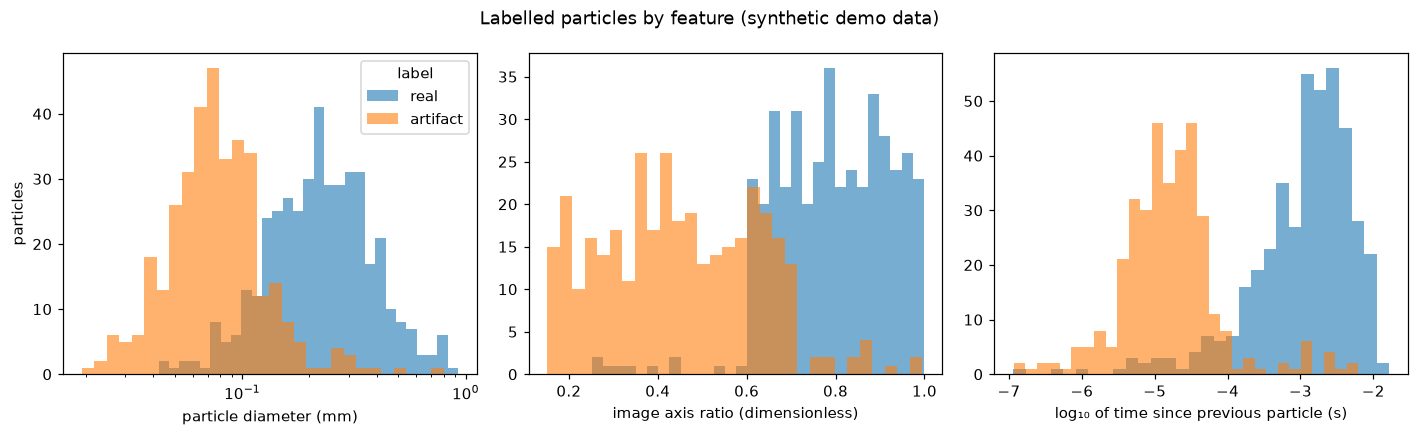

In [6]:
import matplotlib.pyplot as plt

axis_words = {"image_diam_minR": "particle diameter (mm)",
              "image_axis_ratio": "image axis ratio (dimensionless)",
              "log10_inter_arrival": "log₁₀ of time since previous particle (s)"}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, log in zip(axes, ["image_diam_minR", "image_axis_ratio", "log10_inter_arrival"],
                        [True, False, False]):
    for t, colour, lab in [(1, "tab:blue", "real"), (0, "tab:orange", "artifact")]:
        v = table.loc[table.target == t, col]
        bins = np.geomspace(v.min(), v.max(), 30) if log else 30
        ax.hist(v, bins=bins, alpha=0.6, color=colour, label=lab)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(axis_words[col], fontsize=10)
    ax.tick_params(labelsize=10)
axes[0].set_ylabel("particles", fontsize=10)
axes[0].legend(title="label", fontsize=10, title_fontsize=10)
fig.suptitle("Labelled particles by feature (synthetic demo data)", fontsize=12)
fig.tight_layout()

*Figure 1. Distributions of three table features for particles labelled real (blue) and artifact (orange): the particle diameter on a logarithmic axis, the image axis ratio, and the base-10 logarithm of the time since the previous particle. Synthetic demo data.*

## A split by file, not by row

Particles from one file share conditions, so a random row split puts near-copies of the same
conditions on both sides and flatters the score. Holding out whole files measures how a model does
on a file it has never seen. Two files are held out for testing, and the check confirms no file is
on both sides.

In [7]:
test_files = sorted(str(f) for f in rng.choice(FILES, size=2, replace=False))
is_test = table.file.isin(test_files)
train, test = table[~is_test], table[is_test]
assert set(train.file).isdisjoint(test.file)
print(f"train: {len(train)} rows from {sorted(train.file.unique())}")
print(f"test:  {len(test)} rows from {test_files}")

train: 497 rows from ['synthetic_A', 'synthetic_B', 'synthetic_D', 'synthetic_F']
test:  274 rows from ['synthetic_C', 'synthetic_E']


## A baseline model on the grouped split

A plain logistic regression written with NumPy (standardised features, gradient descent), so the
notebook needs no machine-learning library; any library model takes the same features, targets
and file groups. The score is accuracy on the held-out files, beside the share of the majority
class.

In [8]:
def fit_logistic(X, y, steps=3000, lr=0.1):
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(steps):
        p = 1 / (1 + np.exp(-(X @ w + b)))
        w -= lr * X.T @ (p - y) / len(y)
        b -= lr * np.mean(p - y)
    return w, b

mu, sd = train[FEATURES].mean(), train[FEATURES].std()
Xtr = ((train[FEATURES] - mu) / sd).to_numpy()
Xte = ((test[FEATURES] - mu) / sd).to_numpy()
w, b = fit_logistic(Xtr, train.target.to_numpy())
pred = (1 / (1 + np.exp(-(Xte @ w + b)))) > 0.5
acc = np.mean(pred == test.target.to_numpy())
majority = max(test.target.mean(), 1 - test.target.mean())
print(f"held-out files: accuracy {acc:.3f} (majority class {majority:.3f})")
for f, c in zip(FEATURES, w):
    print(f"  {f:22s} weight {c:+.2f}")

held-out files: accuracy 0.949 (majority class 0.544)
  image_diam_minR        weight +0.37
  image_axis_ratio       weight +0.99
  area_ratio             weight +0.67
  image_touching_edge    weight -0.41
  log10_inter_arrival    weight +1.79


## Summary

- Per-particle measurements are the features; triage verdicts, keyed by particle index in one
  sidecar per file, are the targets.
- Only `human` labels with a verdict other than `unsure` or `mixed` are used as ground truth;
  bulk-propagated labels stay in the record but are not trained on.
- The split holds out whole files, checked disjoint, so the score describes files the model has
  not seen.